# Sección 2 · Limpieza de datos con reglas explícitas

En la Sección 1 encontramos varios tipos de problemas. Aquí decidimos qué hacer con cada uno.

### Principio de esta sección
> **Corregir solo cuando los propios datos dicen cuál es el valor correcto. Si no lo dicen, marcar el dato como faltante (`NaN`). Nunca inventar.**

Y una segunda regla: **cada cambio queda registrado en una bitácora** (qué fila, qué regla, valor anterior y valor nuevo). Así cualquier persona, incluido tu profesor, puede auditar la limpieza.

**Lo que NO hacemos aquí:**
- No rellenamos los meses faltantes. Eso es una decisión de modelado y va en la Sección 4.
- No borramos localidades. Solo las marcamos como "elegibles o no" para modelar.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path("../figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

df = pd.read_csv("../datos/interim/s1_renombrado.csv", parse_dates=["fecha", "fecha_dmax"])
original = df.copy()          # copia intacta para comparar al final
print(df.shape)

(3294, 15)


In [2]:
# Bitácora: cada corrección queda registrada aquí
bitacora = []

def registrar(mascara, regla, columna, nuevos_valores):
    # Aplica el cambio a df[columna] en las filas de 'mascara' y lo anota en la bitácora
    idx = df.index[mascara]
    nuevos = pd.Series(nuevos_valores, index=df.index)[idx] if np.ndim(nuevos_valores) else pd.Series(nuevos_valores, index=idx)
    for i in idx:
        bitacora.append({"fila": i, "id_loc": df.at[i, "id_loc"], "localidad": df.at[i, "localidad"],
                         "fecha": df.at[i, "fecha"].date(), "regla": regla, "columna": columna,
                         "antes": df.at[i, columna], "despues": nuevos[i]})
    df.loc[idx, columna] = nuevos
    print(f"{regla:<45} → {len(idx):>3} filas modificadas en '{columna}'")

## 2.1 La herramienta clave: el factor de carga

¿Cómo sabemos si un número está mal **sin tener otra fuente** con qué compararlo? Usamos la física. Las tres variables de una fila tienen que ser coherentes entre sí:

$$FC = \frac{E_{mes}}{P_{max} \times h_{día} \times días}$$

El **factor de carga** (*FC*) compara la energía real del mes con la máxima posible si el sistema hubiera operado todo el tiempo a su pico.

- Siempre está **entre 0 y 1**: no se puede entregar más energía que la que permite el pico.
- En la Sección 1 vimos que **casi siempre ronda 0,75**.
- Si en una fila da 0,0075, es decir **100 veces menos** de lo normal, una de las variables tiene un error de escala.

Para comparar, calculamos el FC "normal" **de cada localidad** (su mediana, usando solo filas con FC entre 0,3 y 1). Luego medimos cuántas potencias de 10 se aleja cada fila:

$$desvío = \log_{10}\left(\frac{FC_{fila}}{FC_{normal}}\right)$$

Un desvío de −2 significa que el FC es 100 veces menor de lo esperado.

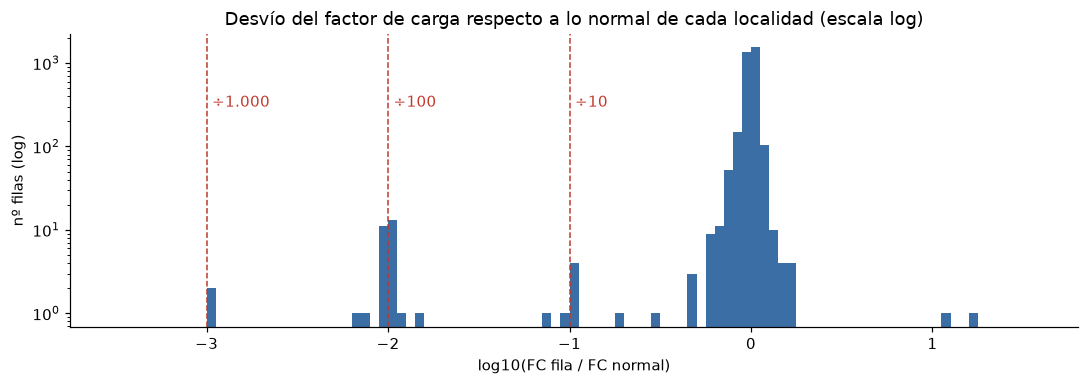

In [3]:
def calcular_referencias(d):
    dias = d.fecha.dt.days_in_month
    d["fc"] = d.e_activa / (d.pot_max * d.horas_dia * dias)
    normal = d.fc.between(0.3, 1.0)
    for c in ["e_activa", "pot_max", "fc"]:
        d["ref_" + c] = d[normal].groupby("id_loc")[c].median().reindex(d.id_loc).values
    d["ref_fc"] = d.ref_fc.fillna(0.75)     # localidades sin filas normales: valor típico global
    with np.errstate(divide="ignore", invalid="ignore"):
        d["desvio_fc"] = np.log10(d.fc / d.ref_fc)                 # ¿la fila es coherente?
        d["desvio_p"] = np.log10(d.pot_max / d.ref_pot_max)        # ¿la potencia es la de siempre?
        d["desvio_e"] = np.log10(d.e_activa / d.ref_e_activa)      # ¿la energía es la de siempre?
    return d

df = calcular_referencias(df)
x = df.desvio_fc.replace([np.inf, -np.inf], np.nan).dropna()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(x, bins=np.arange(-3.5, 1.6, 0.05), color="#3b6ea5")
ax.set_yscale("log")
for k in [-1, -2, -3]:
    ax.axvline(k, color="#c0392b", ls="--", lw=1); ax.text(k + 0.03, 300, f"÷{10**-k:,}".replace(",", "."), color="#c0392b")
ax.set(title="Desvío del factor de carga respecto a lo normal de cada localidad (escala log)",
       xlabel="log10(FC fila / FC normal)", ylabel="nº filas (log)")
fig.tight_layout(); fig.savefig(FIG / "s2_desvio_fc.png"); plt.show()

**Esta gráfica es la evidencia central de la limpieza.** Casi todas las filas están en 0 (coherentes). Las que fallan **no se reparten al azar**: se agrupan exactamente en −1, −2 y −3, es decir ÷10, ÷100 y ÷1000.

Eso no es ruido: es la huella de **errores de digitación o de unidades**:
- −2 (÷100): se perdió la coma decimal con dos decimales (`48.00` registrado como `4800`).
- −3 (÷1000): se registró en W en lugar de kW, o en MWh en lugar de kWh.
- −1 (÷10): se perdió un dígito.

Como el factor es una potencia exacta de 10, **sabemos cuál es el valor correcto** y podemos corregirlo con seguridad.

## 2.2 Regla R1 · Errores de escala (potencias de 10)

Sabemos que la fila es incoherente, pero ¿cuál de las dos variables está mal, la potencia o la energía? Lo decide la historia de la localidad:

- Si **la potencia** es 10ᵏ veces mayor que su valor habitual → dividir la potencia entre 10ᵏ.
- Si **la energía** es 10ᵏ veces menor que su valor habitual → multiplicar la energía por 10ᵏ.
- Si no queda claro cuál es → no se corrige (lo revisa la regla R3).

Tolerancia: el desvío debe estar a menos de 0,25 de un entero (±0,25 en log10 equivale a un factor de ~1,8).

In [4]:
k = (-df.desvio_fc).round()
es_escala = k.isin([1, 2, 3]) & ((df.desvio_fc + k).abs() < 0.25)
culpa_p = es_escala & ((df.desvio_p - k).abs() < 0.4)
culpa_e = es_escala & ~culpa_p & ((df.desvio_e + k).abs() < 0.4)

print("Filas con error de escala:", es_escala.sum(), "| potencia:", culpa_p.sum(), "| energía:", culpa_e.sum(),
      "| sin decidir:", (es_escala & ~culpa_p & ~culpa_e).sum())
registrar(culpa_p, "R1 escala potencia (÷10^k)", "pot_max", df.pot_max / 10 ** k)
registrar(culpa_e, "R1 escala energía (×10^k)", "e_activa", (df.e_activa * 10 ** k).round())
pd.DataFrame(bitacora)[["localidad", "fecha", "columna", "antes", "despues"]].assign(
    localidad=lambda t: t.localidad.str.split(" [(]", regex=True).str[0])

Filas con error de escala: 36 | potencia: 29 | energía: 7 | sin decidir: 0
R1 escala potencia (÷10^k)                    →  29 filas modificadas en 'pot_max'
R1 escala energía (×10^k)                     →   7 filas modificadas en 'e_activa'


,localidad,fecha,columna,antes,despues
0,CAPURGANÁ,2020-04-01,pot_max,47027.0,470.27
1,CAPURGANÁ,2020-05-01,pot_max,48259.0,482.59
2,NOANAMITO,2020-08-01,pot_max,4800.0,48.00
3,EL VALLE,2020-08-01,pot_max,29700.0,297.00
4,BETÉ,2020-08-01,pot_max,7600.0,76.00
5,SAN JOSÉ DEL TAPAJE,2020-08-01,pot_max,8800.0,88.00
6,PITAL DE LA COSTA,2020-08-01,pot_max,7600.0,76.00
7,CAPURGANÁ,2020-09-01,pot_max,45654.0,456.54
8,BETÉ,2020-09-01,pot_max,7200.0,72.00
9,NOANAMITO,2020-10-01,pot_max,3600.0,36.00


**Lectura de la tabla:**
- La mayoría son potencias ×100 concentradas entre **agosto de 2020 y enero de 2021** en veredas del Pacífico. Que caigan en el mismo periodo sugiere un problema en el formato de carga de esos meses, no errores aislados.
- **San Andrés, abril de 2021:** potencia de 2.694.319 → 26.943 kW, coherente con su nivel habitual (~29.000 kW).
- **Leticia, diciembre de 2020:** la energía venía en **MWh** (3.738), así que se multiplica por 1000 → 3.738.000 kWh. La energía reactiva lo confirma: era 317 veces la activa, cuando lo normal es 0,37.
- **Marzo de 2021:** seis localidades con energía ÷10, todas en el mismo mes. Es otro error de carga del reporte.

## 2.3 Regla R2 · Horas de servicio = 0 con energía > 0

Si se entregaron 3,4 millones de kWh, el servicio **no** pudo durar 0 horas. El valor correcto no se puede deducir con certeza (podría ser 24 h o 23,5 h), así que la regla es: `horas_dia` → **NaN**.

`horas_dia` no es la variable objetivo, así que esto no nos hace perder meses para el modelo.

In [5]:
registrar((df.horas_dia == 0) & (df.e_activa > 0), "R2 horas=0 con energía>0", "horas_dia", np.nan)

R2 horas=0 con energía>0                      →   3 filas modificadas en 'horas_dia'


## 2.4 Regla R3 · Registros inconsistentes que no se pueden corregir

Hay filas con un problema real pero sin una corrección segura. Usamos dos verificaciones independientes:

**R3a · Registro de otra localidad.** La energía **y** la potencia se alejan más de 10 veces de lo habitual, en la misma dirección. Ejemplos: Leticia en noviembre de 2020 (2.925 kWh y 20 kW, cuando lo normal es 3,7 millones de kWh y 7.300 kW) y Puerto Conto en mayo de 2020 (83 veces su energía normal). La fila es internamente coherente, pero **no corresponde a esa localidad**.

**R3b · La energía reactiva contradice a la activa.** En todo el dataset la reactiva ronda el 37 % de la activa. Si después de R1 la reactiva sigue siendo **más de 3 veces** la activa, la energía activa de esa fila no es creíble.

En ambos casos: energía (y potencia y horas en R3a) → **NaN**.

In [6]:
df = calcular_referencias(df)   # recalcular con las correcciones de R1
ajeno = (df.desvio_e.abs() > 1) & (df.desvio_p.abs() > 1) & (np.sign(df.desvio_e) == np.sign(df.desvio_p)) & (df.e_activa > 0)
for col in ["e_activa", "pot_max", "horas_dia"]:
    registrar(ajeno, "R3a registro de otra localidad", col, np.nan)

reactiva_rara = (df.e_reactiva > 3 * df.e_activa) & (df.e_activa > 0)
registrar(reactiva_rara, "R3b reactiva > 3× activa", "e_activa", np.nan)

R3a registro de otra localidad                →   2 filas modificadas en 'e_activa'
R3a registro de otra localidad                →   2 filas modificadas en 'pot_max'
R3a registro de otra localidad                →   2 filas modificadas en 'horas_dia'
R3b reactiva > 3× activa                      →   1 filas modificadas en 'e_activa'


## 2.5 Regla R4 · Meses sin servicio y con servicio parcial (son reales, se conservan)

No todo valor raro es un error. Los 15 meses con **energía = 0** tienen también **potencia = 0 y horas = 0**: los tres datos coinciden en que **el sistema no operó** (falla, falta de combustible o mantenimiento). Eso es información real sobre las ZNI y **se conserva**.

Lo mismo con meses de energía muy baja pero coherentes con pocas horas de servicio (por ejemplo, 0,36 horas al día): son **servicio parcial**.

Creamos banderas para que el modelo, o la evaluación, puedan tratarlos aparte:
- `sin_servicio`: energía ≈ 0 (menos de 5 kWh en el mes)
- `servicio_parcial`: horas del mes por debajo del 25 % de lo habitual en la localidad

In [7]:
df["sin_servicio"] = df.e_activa.fillna(np.inf) < 5
ref_h = df.groupby("id_loc").horas_dia.transform("median")
df["servicio_parcial"] = (df.horas_dia < 0.25 * ref_h) & ~df.sin_servicio
print("Meses sin servicio:", df.sin_servicio.sum(), "| con servicio parcial:", df.servicio_parcial.sum())

Meses sin servicio: 18 | con servicio parcial: 24


### ¿Quedan filas "imposibles" (FC > 1)?

In [8]:
df = calcular_referencias(df)
imposibles = df[(df.fc > 1.05) & np.isfinite(df.fc)]
imposibles[["localidad", "fecha", "e_activa", "pot_max", "horas_dia", "fc"]].round({"fc": 2})

,localidad,fecha,e_activa,pot_max,horas_dia,fc
63,CHAJAL (TUMACO - NARIÑO),2020-01-01,3350.0,145.55,0.55,1.35
200,COMUNIDAD INDÍGENA DE PANGUÍ - EL YUCAL (NUQUÍ...,2020-03-01,62.0,4.76,0.33,1.27
334,LOS BRAZOS (TIMBIQUÍ - CAUCA),2020-05-01,246.0,15.38,0.36,1.43
439,CHAJAL (TUMACO - NARIÑO),2020-06-01,3043.0,130.59,0.54,1.44
633,SANTA ROSA DE SAIJA (TIMBIQUÍ - CAUCA),2020-09-01,245.0,27.00,0.28,1.08
1460,LAS MERCEDES (EL CHARCO - NARIÑO),2021-07-01,1921.0,15.87,3.41,1.15
1534,PUERTO JAGUA (NUQUÍ - CHOCÓ),2021-08-01,880.0,3.29,7.39,1.17
2871,SAN ROQUE (MEDIO ATRATO (BETÉ) - CHOCÓ),2023-01-01,1.0,2.54,0.01,1.27
2966,PEÑAS BLANCAS (RIOSUCIO - CHOCÓ),2023-02-01,20.0,2.70,0.03,8.82
3125,PEÑAS BLANCAS (RIOSUCIO - CHOCÓ),2023-04-01,114.0,2.04,0.15,12.42


Las que quedan son veredas con **muy pocas horas de servicio** (0,03 a 0,6 h/día). Ahí el FC se dispara por el **redondeo de las horas**: 0,33 h y 0,40 h parecen casi iguales, pero cambian el FC en un 20 %. Tienen un solo decimal: en ~1 hora de servicio, el redondeo pesa mucho.

**Decisión:** se conservan (la energía es plausible) y se marcan con `fc_dudoso`. Peñas Blancas, con FC entre 8 y 12, se trata en la regla R8: es un sistema casi inexistente.

In [9]:
df["fc_dudoso"] = (df.fc > 1.05) & np.isfinite(df.fc)
print("Filas marcadas fc_dudoso:", df.fc_dudoso.sum())

Filas marcadas fc_dudoso: 10


## 2.6 Regla R5 · Nombre único por localidad

Un mismo `id_loc` aparece con más de un nombre (por ejemplo "CHOCO" y "CHOCÓ"). Se deja **un nombre canónico**: el más frecuente. De todas formas, siempre se agrupa por `id_loc`.

In [10]:
canon = df.groupby("id_loc").localidad.agg(lambda s: s.value_counts().index[0])
cambia = df.localidad != df.id_loc.map(canon)
registrar(cambia, "R5 nombre canónico", "localidad", df.id_loc.map(canon))
df["nombre_corto"] = df.localidad.str.split(" [(]", regex=True).str[0].str.title()

R5 nombre canónico                            →   1 filas modificadas en 'localidad'


## 2.7 Regla R6 · Calendario mensual completo (huecos explícitos)

Hoy un mes faltante es **una fila que no existe**. Eso es peligroso: si calculamos "el valor del mes anterior" con `shift(1)` y falta un mes, el código toma en realidad **el de hace dos meses** sin avisar.

Solución: cada localidad tiene una fila por mes, **desde su primer hasta su último reporte**. Los meses faltantes quedan con `NaN` y la bandera `mes_faltante = True`. **No se rellenan aquí**: la estrategia de relleno es una decisión del modelo (Sección 4).

In [11]:
filas = []
for loc, s in df.groupby("id_loc"):
    meses = pd.date_range(s.fecha.min(), s.fecha.max(), freq="MS")
    filas.append(pd.DataFrame({"id_loc": loc, "fecha": meses}))
malla = pd.concat(filas, ignore_index=True)

estaticas = ["id_depto", "depto", "id_mpio", "mpio", "localidad", "nombre_corto"]
info = df.groupby("id_loc")[estaticas].first()
panel = (malla.merge(df.drop(columns=estaticas), on=["id_loc", "fecha"], how="left")
              .merge(info, left_on="id_loc", right_index=True))
panel["mes_faltante"] = panel.anio.isna()
panel["anio"], panel["mes"] = panel.fecha.dt.year, panel.fecha.dt.month
for b in ["sin_servicio", "servicio_parcial", "fc_dudoso"]:
    panel[b] = panel[b].astype("boolean").fillna(False).astype(bool)
print("Filas antes:", len(df), "→ con calendario completo:", len(panel), "| meses faltantes explícitos:", panel.mes_faltante.sum())

Filas antes: 3294 → con calendario completo: 3769 | meses faltantes explícitos: 475


## 2.8 Regla R7 · Indicador del periodo COVID-19

En Colombia, el aislamiento preventivo obligatorio rigió de **marzo a agosto de 2020**, con reapertura gradual hasta finales de año. Vimos que San Andrés, que depende del turismo, cayó cerca de 25 %.

**No borramos 2020**: perderíamos el 30 % de la historia. Creamos la variable `covid` (1 entre marzo y diciembre de 2020). En la Sección 3 medimos su efecto real y en la Sección 4 decidimos cómo usarla.

In [12]:
panel["covid"] = panel.fecha.between("2020-03-01", "2020-12-01").astype(int)

## 2.9 Regla R8 · ¿Qué localidades se pueden modelar?

Para pronosticar una serie necesitamos **suficiente historia** y un **consumo real**. Criterios (se marcan, no se borran):
1. **≥ 24 meses con energía válida.** Mínimo para ver dos ciclos anuales y tener meses de prueba.
2. **Mediana de energía ≥ 100 kWh/mes.** Por debajo, la "localidad" opera unas pocas horas al año (Peñas Blancas: 19 kWh/mes; Macedonia: 0) y su comportamiento es sobre todo operativo, no de demanda.

In [13]:
res = panel.groupby("id_loc").agg(nombre=("nombre_corto", "first"), depto=("depto", "first"),
                                  meses_validos=("e_activa", lambda s: s.notna().sum()),
                                  mediana_kwh=("e_activa", "median"))
res["elegible"] = (res.meses_validos >= 24) & (res.mediana_kwh >= 100)
panel["elegible"] = panel.id_loc.map(res.elegible)
tot = panel.e_activa.sum()
print(f"Localidades elegibles: {res.elegible.sum()} de {len(res)}  "
      f"({panel.loc[panel.elegible, 'e_activa'].sum() / tot:.1%} de la energía total)")
print("\nNo elegibles por poca historia:", ((res.meses_validos < 24)).sum(),
      "| por consumo mínimo:", ((res.meses_validos >= 24) & (res.mediana_kwh < 100)).sum())
res.sort_values("mediana_kwh").head(6)

Localidades elegibles: 78 de 133  (99.2% de la energía total)

No elegibles por poca historia: 55 | por consumo mínimo: 0


,nombre,depto,meses_validos,mediana_kwh,elegible
id_loc,,,,,
27450016,Macedonia,CHOCÓ,5,0.0,False
27615930,Peñas Blancas,CHOCÓ,4,19.5,False
52427910,El Rosario,NARIÑO,1,68.0,False
27615912,Marcial,CHOCÓ,4,91.0,False
52427913,La Isla,NARIÑO,3,129.0,False
52427013,La Loma,NARIÑO,6,552.0,False


**Lectura:** las 78 localidades elegibles concentran el **99,2 % de la energía**. Las 55 que quedan fuera son, casi todas, veredas que entraron tarde al monitoreo (en 2022–2023) o que reportaron pocos meses.

El criterio de consumo mínimo no excluyó a nadie más: los micro-sistemas (Macedonia, Peñas Blancas, Marcial) **ya tenían menos de 24 meses**. Lo dejamos escrito igual, porque si se actualizan los datos con meses nuevos, el filtro sigue protegiendo el modelo.

## 2.10 Verificación: ¿quedó bien?

Repetimos los chequeos de la Sección 1 sobre los datos limpios y miramos algunas series antes y después.

In [14]:
p = calcular_referencias(panel.copy())
dias = p.fecha.dt.days_in_month
chequeos = pd.DataFrame({
    "Sección 1 (original)": [
        (original.pot_max > 50 * original.groupby("id_loc").pot_max.transform("median")).sum(),
        ((original.horas_dia == 0) & (original.e_activa > 0)).sum(),
        (original.e_reactiva > 3 * original.e_activa).sum()],
    "Después de limpiar": [
        (p.pot_max > 50 * p.groupby("id_loc").pot_max.transform("median")).sum(),
        ((p.horas_dia == 0) & (p.e_activa > 0)).sum(),
        ((p.e_reactiva > 3 * p.e_activa) & p.e_activa.notna()).sum()]},
    index=["potencia > 50× su mediana", "horas = 0 con energía", "reactiva > 3× activa"])
chequeos

,Sección 1 (original),Después de limpiar
potencia > 50× su mediana,29,1
horas = 0 con energía,3,0
reactiva > 3× activa,7,0


El único caso que queda en "potencia > 50×" es **Macedonia (mayo de 2023)**. No es un error: esa localidad tuvo 4 meses con potencia 0, así que su mediana es 0 y **cualquier** valor positivo dispara el chequeo. Su energía (161 kWh), potencia (2,9 kW) y horas (2 h) son coherentes entre sí (FC ≈ 0,88). Igual queda fuera del modelado por la regla R8.

**Lección:** un chequeo automático también puede equivocarse. Por eso cada caso marcado se revisa a mano antes de corregirlo.

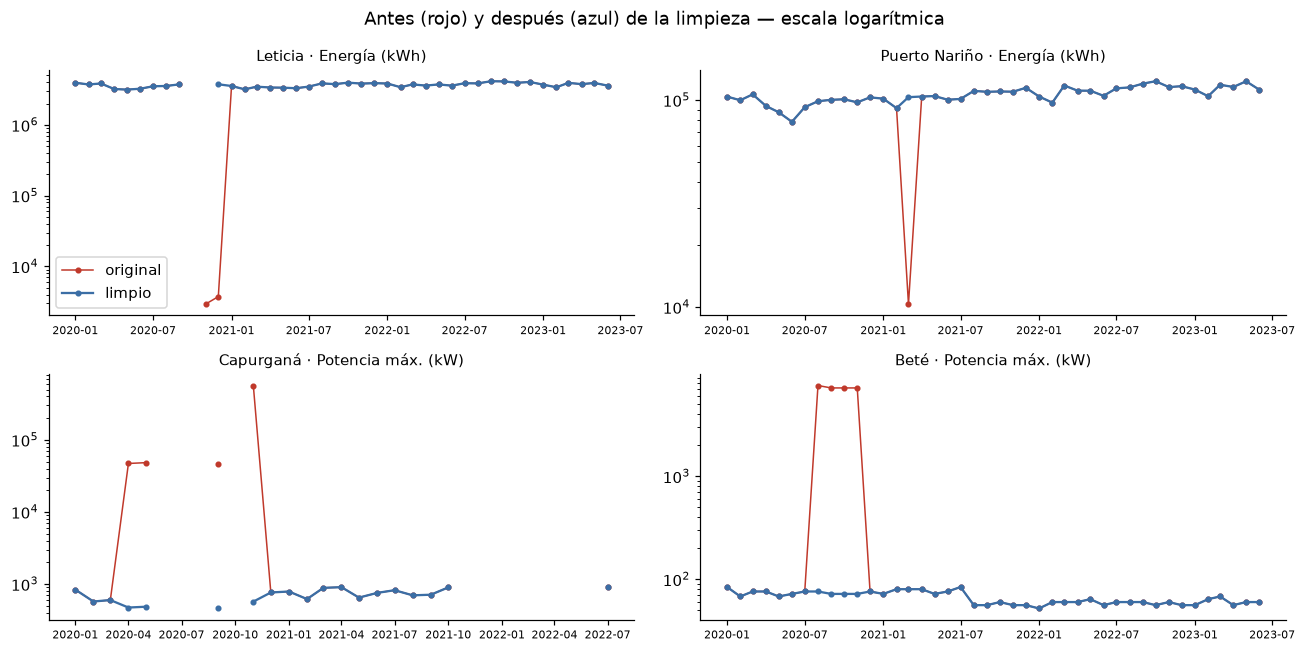

In [15]:
casos = [("Leticia", "e_activa", "Energía (kWh)"), ("Puerto Nariño", "e_activa", "Energía (kWh)"),
         ("Capurganá", "pot_max", "Potencia máx. (kW)"), ("Beté", "pot_max", "Potencia máx. (kW)")]
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (nom, col, lab) in zip(axes.flat, casos):
    idl = panel.loc[panel.nombre_corto == nom, "id_loc"].iloc[0]
    a = original[original.id_loc == idl].set_index("fecha")[col].asfreq("MS")
    b = panel[panel.id_loc == idl].set_index("fecha")[col]
    ax.plot(a.index, a.values, color="#c0392b", marker="o", ms=3, lw=1, label="original")
    ax.plot(b.index, b.values, color="#3b6ea5", marker="o", ms=3, lw=1.5, label="limpio")
    ax.set_yscale("log"); ax.set_title(f"{nom} · {lab}", fontsize=10); ax.tick_params(axis="x", labelsize=7)
axes[0, 0].legend()
fig.suptitle("Antes (rojo) y después (azul) de la limpieza — escala logarítmica")
fig.tight_layout(); fig.savefig(FIG / "s2_antes_despues.png"); plt.show()

En escala logarítmica, un error ×100 se ve como un salto de "dos escalones". Después de limpiar, las series azules quedan **continuas en su nivel habitual**. Donde el dato no se podía recuperar (Leticia en noviembre de 2020) queda un **hueco**, no un valor inventado.

## 2.11 Guardar resultados

In [16]:
Path("../datos/processed").mkdir(parents=True, exist_ok=True)
cols = ["id_loc", "nombre_corto", "localidad", "id_depto", "depto", "id_mpio", "mpio", "fecha", "anio", "mes",
        "e_activa", "e_reactiva", "pot_max", "horas_dia", "dia_dmax", "fecha_dmax",
        "mes_faltante", "sin_servicio", "servicio_parcial", "fc_dudoso", "covid", "elegible"]
panel[cols].sort_values(["id_loc", "fecha"]).to_csv("../datos/processed/energia_limpia.csv", index=False)
bit = pd.DataFrame(bitacora); bit.to_csv("../datos/processed/bitacora_limpieza.csv", index=False)
res.to_csv("../datos/processed/localidades.csv")
print("energia_limpia.csv:", len(panel), "filas | bitácora:", len(bit), "cambios")
bit.groupby(["regla", "columna"]).size().to_frame("filas")

energia_limpia.csv: 3769 filas | bitácora: 47 cambios


filas
regla                          columna         
R1 escala energía (×10^k)      e_activa       7
R1 escala potencia (÷10^k)     pot_max       29
R2 horas=0 con energía>0       horas_dia      3
R3a registro de otra localidad e_activa       2
                               horas_dia      2
                               pot_max        2
R3b reactiva > 3× activa       e_activa       1
R5 nombre canónico             localidad      1

## Resumen de la Sección 2

| Regla | Problema | Decisión | Por qué |
|---|---|---|---|
| R1 | Errores de escala ×10, ×100 y ×1000 | **Corregir** dividiendo o multiplicando por 10ᵏ | El factor de carga muestra la potencia exacta de 10; el valor correcto se puede deducir |
| R2 | Horas = 0 con energía | **NaN** en horas | Imposible, pero el valor correcto no se puede deducir |
| R3 | Registros de otra localidad / reactiva incoherente | **NaN** | Hay error, pero no hay forma segura de corregirlo |
| R4 | Meses sin servicio o con servicio parcial | **Conservar + bandera** | Son eventos reales de las ZNI |
| R5 | Nombres inconsistentes | Nombre canónico | Evita duplicar series |
| R6 | Meses ausentes | Calendario completo con `NaN` + bandera | Evita rezagos (`shift`) equivocados |
| R7 | Choque COVID-19 | Variable indicadora | No se borra historia; se mide en la Sección 3 |
| R8 | Series muy cortas o micro-sistemas | Bandera `elegible` | Se decide qué se modela sin borrar nada |

**Archivos generados:**
- `datos/processed/energia_limpia.csv`: panel limpio con banderas.
- `datos/processed/bitacora_limpieza.csv`: cada cambio, con su valor antes y después.
- `datos/processed/localidades.csv`: resumen y elegibilidad por localidad.

**Siguiente — Sección 3 (análisis exploratorio para series de tiempo):** tendencia, estacionalidad, autocorrelación (¿cuánto se parece un mes al anterior?) y el efecto real del COVID. Eso nos dirá qué variables vale la pena construir para el modelo.